In [80]:
import pandas as pd
import numpy as np

# Load Round 2 Dataset
df = pd.read_csv("../data/raw/Labeled_Social_NLP_Training_Data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (9000, 4)


,text_id,post_text,sentiment_label,topic_category
0,TXT_00001,some1 come wait in line with me Thursday at 3@target bc briana is being a bitch,Negative,Community_Discussion
1,TXT_00002,Mancity strikers Aguero and Dzeko you better thrash Bolton tomorrow night!,Positive,Community_Discussion
2,TXT_00003,Would you like to join us at our annual gala at the Sandman Signature Resort on Oct 25? Contact our centre at 6042773100 for tickets!,Positive,Community_Discussion
3,TXT_00004,"""Sicily may form grand coalition, Italian UDC Party leader: (AGI) Rome - On Monday Rocco Buttiglione, the leader ...",Neutral,Community_Discussion
4,TXT_00005,@user @user If the comment was in reference to the 'Charlie Hebdo' violent attack in january: it is no less repugnant. In my opinion,Negative,Community_Discussion


In [81]:
# Dataset structure audit

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(9000, 4)

Column Names:
['text_id', 'post_text', 'sentiment_label', 'topic_category']

Data Types:
text_id            str
post_text          str
sentiment_label    str
topic_category     str
dtype: object

Missing Values:
text_id            0
post_text          0
sentiment_label    0
topic_category     0
dtype: int64


In [82]:
# Check label distribution

print("Sentiment Label Distribution:")
print(df["sentiment_label"].value_counts())

print("\nTopic Category Distribution:")
print(df["topic_category"].value_counts())

Sentiment Label Distribution:
sentiment_label
Negative    3000
Positive    3000
Neutral     3000
Name: count, dtype: int64

Topic Category Distribution:
topic_category
Community_Discussion    7752
Technical_Issues         815
Feature_Feedback         297
Account_Security         136
Name: count, dtype: int64


In [83]:
# Check duplicate IDs and duplicate text

print("Duplicate text_id:", df["text_id"].duplicated().sum())
print("Duplicate post_text:", df["post_text"].duplicated().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Duplicate text_id: 0
Duplicate post_text: 1100

Duplicate rows: 0


In [84]:
# Check whether duplicate texts have consistent sentiment labels

duplicate_texts = df[df["post_text"].duplicated(keep=False)].copy()

label_consistency = (
    duplicate_texts
    .groupby("post_text")["sentiment_label"]
    .nunique()
)

print("Total duplicate text records:", len(duplicate_texts))
print("Unique duplicated texts:", duplicate_texts["post_text"].nunique())
print("Texts with multiple sentiment labels:", (label_consistency > 1).sum())
print("Texts with one consistent sentiment label:", (label_consistency == 1).sum())

Total duplicate text records: 2087
Unique duplicated texts: 987
Texts with multiple sentiment labels: 0
Texts with one consistent sentiment label: 987


In [85]:
# Text quality audit

df["text_length"] = df["post_text"].str.len()
df["word_count"] = df["post_text"].str.split().str.len()

print("Text Length Statistics:")
print(df["text_length"].describe())

print("\nWord Count Statistics:")
print(df["word_count"].describe())

print("\nEmpty / Whitespace-only texts:",
      df["post_text"].str.strip().eq("").sum())

print("\nURLs:", df["post_text"].str.contains(r"http|www\.", case=False, regex=True).sum())

print("Mentions:", df["post_text"].str.contains(r"@\w+", regex=True).sum())

print("Hashtags:", df["post_text"].str.contains(r"#\w+", regex=True).sum())

Text Length Statistics:
count    9000.000000
mean      107.985778
std        26.104963
min        25.000000
25%        91.000000
50%       113.000000
75%       129.000000
max       180.000000
Name: text_length, dtype: float64

Word Count Statistics:
count    9000.000000
mean       19.472111
std         4.933866
min         4.000000
25%        16.000000
50%        20.000000
75%        23.000000
max        35.000000
Name: word_count, dtype: float64

Empty / Whitespace-only texts: 0

URLs: 17
Mentions: 2659
Hashtags: 1573


In [86]:
# Inspect sample texts

pd.set_option("display.max_colwidth", 200)

df[["post_text", "sentiment_label", "topic_category"]].sample(
    10, random_state=42
)

,post_text,sentiment_label,topic_category
7940,Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!,Negative,Community_Discussion
1162,Enjoying feasibility workshop replacing #Cognos with @user #BI. 4th customer in less than a year!,Positive,Community_Discussion
582,"""Rick Perry May Not Have an Exit Strategy."" I encourage all Perry supporters to read this. Get the story out there.",Negative,Community_Discussion
4081,"#HLWD: @user is leading the pack for a Mariah Carey ride, tomorrow at 10:45! Grab a bike and end your weekend with a cardio party!",Positive,Community_Discussion
8412,@user the Pro Bowl definitely isn\u2019t better and NBA All-Star game is trash until 4th qtr,Negative,Community_Discussion
8730,"@user George Harrison composed """"Here Comes the Sun"""" at Eric Clapton's house in Surrey.""",Neutral,Community_Discussion
5936,@user wanna go see legally blonde at north at 2 on saturday? i told your mom already but i need to make sure they have tickets if ya want,Neutral,Community_Discussion
8283,"Rick Perry was going to go on Are You Smarter Than a 5th Grader? to win money to continue his campaign, but he's embarrassed himself enough.",Negative,Community_Discussion
3706,Dustin Johnson just took an 8 on the 1st hole. I don't feel so bad about my golf game suddenly. #PGAChampionship #snowman,Negative,Community_Discussion
4071,"@user just like a person may say to me """"I don't agree with Islam&amp;dont want2b a Muslim but u have right to be one"""" same thing""",Neutral,Community_Discussion


In [87]:
# Sentiment distribution across topic categories

topic_sentiment = pd.crosstab(
    df["topic_category"],
    df["sentiment_label"]
)

print(topic_sentiment)

sentiment_label       Negative  Neutral  Positive
topic_category                                   
Account_Security            34       47        55
Community_Discussion      2583     2623      2546
Feature_Feedback           119      104        74
Technical_Issues           264      226       325


In [88]:
print("Sentiment labels:")
print(sorted(df["sentiment_label"].unique()))

print("\nTopic labels:")
print(sorted(df["topic_category"].unique()))

Sentiment labels:
['Negative', 'Neutral', 'Positive']

Topic labels:
['Account_Security', 'Community_Discussion', 'Feature_Feedback', 'Technical_Issues']


In [89]:
# Create a working copy for NLP preprocessing

nlp_df = df[[
    "text_id",
    "post_text",
    "sentiment_label",
    "topic_category"
]].copy()

print("Working dataset shape:", nlp_df.shape)
print("\nColumns:", nlp_df.columns.tolist())

Working dataset shape: (9000, 4)

Columns: ['text_id', 'post_text', 'sentiment_label', 'topic_category']


In [90]:
import html

# Decode HTML entities while preserving the original text
nlp_df["clean_text"] = nlp_df["post_text"].apply(html.unescape)

print("Original:")
print(nlp_df["post_text"].iloc[9])

print("\nAfter HTML decoding:")
print(nlp_df["clean_text"].iloc[9])

Original:
"1st game played under Solar Powered floodlights in the world happened in MYSA,Nairobi Kenya. #PhilipsLED"

After HTML decoding:
"1st game played under Solar Powered floodlights in the world happened in MYSA,Nairobi Kenya. #PhilipsLED"


In [91]:
import re

# Replace URLs and user mentions with standard tokens
nlp_df["clean_text"] = (
    nlp_df["clean_text"]
    .str.replace(r"https?://\S+|www\.\S+", " <URL> ", regex=True)
    .str.replace(r"@\w+", " <USER> ", regex=True)
)

print(nlp_df[["post_text", "clean_text"]].sample(10, random_state=42).to_string(index=False))

                                                                                                                                   post_text                                                                                                                                   clean_text
                                                        Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!                                                         Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!
                                           Enjoying feasibility workshop replacing #Cognos with @user #BI. 4th customer in less than a year!                                         Enjoying feasibility workshop replacing #Cognos with  <USER>  #BI. 4th customer in less than a year!
                         "Rick Perry May Not Have an Exit Strategy." I encourage all Perry supporters to read this. Get the story out there.              

In [92]:
# Remove hashtag symbol while preserving the hashtag word

nlp_df["clean_text"] = (
    nlp_df["clean_text"]
    .str.replace(r"#(\w+)", r"\1", regex=True)
)

print(nlp_df[["post_text", "clean_text"]].sample(10, random_state=42).to_string(index=False))

                                                                                                                                   post_text                                                                                                                                   clean_text
                                                        Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!                                                         Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!
                                           Enjoying feasibility workshop replacing #Cognos with @user #BI. 4th customer in less than a year!                                           Enjoying feasibility workshop replacing Cognos with  <USER>  BI. 4th customer in less than a year!
                         "Rick Perry May Not Have an Exit Strategy." I encourage all Perry supporters to read this. Get the story out there.              

In [93]:
# Normalize multiple spaces into a single space

nlp_df["clean_text"] = (
    nlp_df["clean_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(nlp_df[["post_text", "clean_text"]].sample(10, random_state=42).to_string(index=False))

                                                                                                                                   post_text                                                                                                                                   clean_text
                                                        Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!                                                         Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!
                                           Enjoying feasibility workshop replacing #Cognos with @user #BI. 4th customer in less than a year!                                             Enjoying feasibility workshop replacing Cognos with <USER> BI. 4th customer in less than a year!
                         "Rick Perry May Not Have an Exit Strategy." I encourage all Perry supporters to read this. Get the story out there.              

In [94]:
# Convert text to lowercase

nlp_df["clean_text"] = nlp_df["clean_text"].str.lower()

print(nlp_df[["post_text", "clean_text"]].sample(10, random_state=42).to_string(index=False))

                                                                                                                                   post_text                                                                                                                                   clean_text
                                                        Jordan Rhodes was NOT jeered last night like this bellend in the sun is reporting!!!                                                         jordan rhodes was not jeered last night like this bellend in the sun is reporting!!!
                                           Enjoying feasibility workshop replacing #Cognos with @user #BI. 4th customer in less than a year!                                             enjoying feasibility workshop replacing cognos with <user> bi. 4th customer in less than a year!
                         "Rick Perry May Not Have an Exit Strategy." I encourage all Perry supporters to read this. Get the story out there.              

In [95]:
print("Empty clean texts:", nlp_df["clean_text"].str.strip().eq("").sum())

print(
    "Duplicate clean texts:",
    nlp_df["clean_text"].duplicated().sum()
)

print(
    "Total rows:",
    len(nlp_df)
)

Empty clean texts: 0
Duplicate clean texts: 1100
Total rows: 9000


In [96]:
print("Sentiment label counts:")
print(nlp_df["sentiment_label"].value_counts())

print("\nUnique sentiment labels:")
print(nlp_df["sentiment_label"].unique())

Sentiment label counts:
sentiment_label
Negative    3000
Positive    3000
Neutral     3000
Name: count, dtype: int64

Unique sentiment labels:
<StringArray>
['Negative', 'Positive', 'Neutral']
Length: 3, dtype: str


In [97]:
# Create final dataset for sentiment modeling

model_df = nlp_df[
    ["text_id", "post_text", "clean_text", "sentiment_label"]
].copy()

print("Modeling dataset shape:", model_df.shape)

print("\nColumns:")
print(model_df.columns.tolist())

print("\nSample:")
model_df.head()

Modeling dataset shape: (9000, 4)

Columns:
['text_id', 'post_text', 'clean_text', 'sentiment_label']

Sample:


,text_id,post_text,clean_text,sentiment_label
0,TXT_00001,some1 come wait in line with me Thursday at 3@target bc briana is being a bitch,some1 come wait in line with me thursday at 3 <user> bc briana is being a bitch,Negative
1,TXT_00002,Mancity strikers Aguero and Dzeko you better thrash Bolton tomorrow night!,mancity strikers aguero and dzeko you better thrash bolton tomorrow night!,Positive
2,TXT_00003,Would you like to join us at our annual gala at the Sandman Signature Resort on Oct 25? Contact our centre at 6042773100 for tickets!,would you like to join us at our annual gala at the sandman signature resort on oct 25? contact our centre at 6042773100 for tickets!,Positive
3,TXT_00004,"""Sicily may form grand coalition, Italian UDC Party leader: (AGI) Rome - On Monday Rocco Buttiglione, the leader ...","""sicily may form grand coalition, italian udc party leader: (agi) rome - on monday rocco buttiglione, the leader ...",Neutral
4,TXT_00005,@user @user If the comment was in reference to the 'Charlie Hebdo' violent attack in january: it is no less repugnant. In my opinion,<user> <user> if the comment was in reference to the 'charlie hebdo' violent attack in january: it is no less repugnant. in my opinion,Negative


In [98]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

print("ML libraries imported successfully!")

Scikit-learn version: 1.9.0
ML libraries imported successfully!


In [99]:
from sklearn.model_selection import GroupShuffleSplit

# Group by the original text so identical posts stay in the same split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        model_df,
        model_df["sentiment_label"],
        groups=model_df["clean_text"]
    )
)

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

print("\nDuplicate clean texts shared between train and test:",
      len(set(train_df["clean_text"]) & set(test_df["clean_text"])))

Training set: (7183, 4)
Test set: (1817, 4)

Duplicate clean texts shared between train and test: 0


In [100]:
print("Training sentiment distribution:")
print(train_df["sentiment_label"].value_counts())

print("\nTraining sentiment percentage:")
print(train_df["sentiment_label"].value_counts(normalize=True).round(3) * 100)

print("\nTest sentiment distribution:")
print(test_df["sentiment_label"].value_counts())

print("\nTest sentiment percentage:")
print(test_df["sentiment_label"].value_counts(normalize=True).round(3) * 100)

Training sentiment distribution:
sentiment_label
Neutral     2407
Positive    2397
Negative    2379
Name: count, dtype: int64

Training sentiment percentage:
sentiment_label
Neutral     33.5
Positive    33.4
Negative    33.1
Name: proportion, dtype: float64

Test sentiment distribution:
sentiment_label
Negative    621
Positive    603
Neutral     593
Name: count, dtype: int64

Test sentiment percentage:
sentiment_label
Negative    34.2
Positive    33.2
Neutral     32.6
Name: proportion, dtype: float64


In [101]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF feature extraction
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train = tfidf.fit_transform(train_df["clean_text"])

# Transform test data using the same vocabulary
X_test = tfidf.transform(test_df["clean_text"])

y_train = train_df["sentiment_label"]
y_test = test_df["sentiment_label"]

print("TF-IDF feature extraction completed!")
print("Training matrix:", X_train.shape)
print("Test matrix:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF feature extraction completed!
Training matrix: (7183, 25650)
Test matrix: (1817, 25650)
Vocabulary size: 25650


In [102]:
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict on unseen test data
y_pred_lr = lr_model.predict(X_test)

# Calculate overall metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, average="weighted")
recall = recall_score(y_test, y_pred_lr, average="weighted")
f1 = f1_score(y_test, y_pred_lr, average="weighted")

print("Logistic Regression Evaluation")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation
--------------------------------
Accuracy : 0.5883
Precision: 0.5897
Recall   : 0.5883
F1-Score : 0.5888

Classification Report:
              precision    recall  f1-score   support

    Negative       0.63      0.64      0.64       621
     Neutral       0.52      0.54      0.53       593
    Positive       0.62      0.59      0.60       603

    accuracy                           0.59      1817
   macro avg       0.59      0.59      0.59      1817
weighted avg       0.59      0.59      0.59      1817



In [104]:
from sklearn.svm import LinearSVC

# Train Linear SVM
svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

svm_model.fit(X_train, y_train)

print("Linear SVM training completed!")

Linear SVM training completed!


In [105]:
# Predict on the test set
y_pred_svm = svm_model.predict(X_test)

# Calculate evaluation metrics
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average="weighted")
recall_svm = recall_score(y_test, y_pred_svm, average="weighted")
f1_svm = f1_score(y_test, y_pred_svm, average="weighted")

print("Linear SVM Evaluation")
print("---------------------")
print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1-Score : {f1_svm:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Linear SVM Evaluation
---------------------
Accuracy : 0.5757
Precision: 0.5768
Recall   : 0.5757
F1-Score : 0.5762

Classification Report:
              precision    recall  f1-score   support

    Negative       0.63      0.61      0.62       621
     Neutral       0.50      0.51      0.51       593
    Positive       0.60      0.60      0.60       603

    accuracy                           0.58      1817
   macro avg       0.58      0.57      0.58      1817
weighted avg       0.58      0.58      0.58      1817



In [106]:
from sklearn.naive_bayes import MultinomialNB

# Train Multinomial Naive Bayes
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes training completed!")

Multinomial Naive Bayes training completed!


In [107]:
# Predict on the test set
y_pred_nb = nb_model.predict(X_test)

# Calculate evaluation metrics
accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb, average="weighted")
recall_nb = recall_score(y_test, y_pred_nb, average="weighted")
f1_nb = f1_score(y_test, y_pred_nb, average="weighted")

print("Multinomial Naive Bayes Evaluation")
print("----------------------------------")
print(f"Accuracy : {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall   : {recall_nb:.4f}")
print(f"F1-Score : {f1_nb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Multinomial Naive Bayes Evaluation
----------------------------------
Accuracy : 0.5949
Precision: 0.5943
Recall   : 0.5949
F1-Score : 0.5925

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.62      0.64       621
     Neutral       0.54      0.47      0.50       593
    Positive       0.59      0.68      0.63       603

    accuracy                           0.59      1817
   macro avg       0.59      0.59      0.59      1817
weighted avg       0.59      0.59      0.59      1817



In [108]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Generate confusion matrix for Naive Bayes
cm = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=["Negative", "Neutral", "Positive"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Neutral", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
)

print("Naive Bayes Confusion Matrix:")
print(cm_df)

Naive Bayes Confusion Matrix:
                 Predicted Negative  Predicted Neutral  Predicted Positive
Actual Negative                 387                121                 113
Actual Neutral                  133                281                 179
Actual Positive                  70                120                 413


In [109]:
# Error Analysis - Misclassified Predictions

error_df = test_df[[
    "text_id",
    "post_text",
    "sentiment_label"
]].copy()

error_df["predicted_label"] = y_pred_nb

# Keep only misclassified examples
errors = error_df[
    error_df["sentiment_label"] != error_df["predicted_label"]
].copy()

print("Total misclassified samples:", len(errors))

print("\nMost common confusion pairs:")
print(
    errors.groupby(
        ["sentiment_label", "predicted_label"]
    ).size().sort_values(ascending=False)
)

print("\nSample misclassified posts:")
errors.sample(15, random_state=42)

Total misclassified samples: 736

Most common confusion pairs:
sentiment_label  predicted_label
Neutral          Positive           179
                 Negative           133
Negative         Neutral            121
Positive         Neutral            120
Negative         Positive           113
Positive         Negative            70
dtype: int64

Sample misclassified posts:


,text_id,post_text,sentiment_label,predicted_label
8258,TXT_08259,Update to last story - UFC 194 will be December 12 at MGM Grand Garden Arena with Jose Aldo vs. Conor McGregor,Positive,Neutral
330,TXT_00331,Fab &amp; 50's tapes the only shit I been playing lately.. Well add cole and kendrick's Black Friday too of course,Neutral,Negative
6811,TXT_06812,Nuno Espirito Santo has been a nice surprise. Valencia currently 2nd in La Liga. Beat Atletico Madrid on the weekend.,Positive,Neutral
2269,TXT_02270,We want to tell people how great Islam is yet we are not great Muslims. May our actions speak louder than our words.,Neutral,Negative
3136,TXT_03137,I go on channel 7 to see what the weather is gonna be like tomorrow and Taylor Swift singing.. #EEWWW #GETOFFMYTV,Negative,Positive
7261,TXT_07262,Floyd Mayweather may be a good boxer but he sure is a terrible human being.,Negative,Neutral
403,TXT_00404,We add our regrets for yesterday's tragedy at the Pride Parade. May Peace Happen during our time. Shabbat Shalimar,Neutral,Positive
6876,TXT_06877,It seems the rest of my life may just be convincing people to watch Ant-Man with me.,Negative,Positive
7270,TXT_07271,Speaking of Chris Jericho\u002c it is Wednesday today is it not? Time for some catching up on wrestling.,Neutral,Positive
7628,TXT_07629,Just caught the end of TFI Friday. Chris Evans is like the Harold Zidler of Wetherspoons.,Neutral,Positive


In [110]:
# Quantitative Error Analysis

error_counts = (
    errors
    .groupby(["sentiment_label", "predicted_label"])
    .size()
    .reset_index(name="count")
)

total_errors = len(errors)

error_counts["percentage_of_errors"] = (
    error_counts["count"] / total_errors * 100
).round(2)

print("Error Analysis Summary:")
print(error_counts.sort_values("count", ascending=False).to_string(index=False))

Error Analysis Summary:
sentiment_label predicted_label  count  percentage_of_errors
        Neutral        Positive    179                 24.32
        Neutral        Negative    133                 18.07
       Negative         Neutral    121                 16.44
       Positive         Neutral    120                 16.30
       Negative        Positive    113                 15.35
       Positive        Negative     70                  9.51


In [111]:
# Final Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        accuracy,
        accuracy_svm,
        accuracy_nb
    ],
    "Weighted Precision": [
        precision,
        precision_svm,
        precision_nb
    ],
    "Weighted Recall": [
        recall,
        recall_svm,
        recall_nb
    ],
    "Weighted F1": [
        f1,
        f1_svm,
        f1_nb
    ]
})

model_comparison = model_comparison.round(4)

print("Final Model Comparison:")
print(model_comparison.to_string(index=False))

Final Model Comparison:
                  Model  Accuracy  Weighted Precision  Weighted Recall  Weighted F1
    Logistic Regression    0.5883              0.5897           0.5883       0.5888
             Linear SVM    0.5757              0.5768           0.5757       0.5762
Multinomial Naive Bayes    0.5949              0.5943           0.5949       0.5925


In [112]:
import joblib
from pathlib import Path

# Create models directory if it does not exist
Path("../models").mkdir(exist_ok=True)

# Save the trained Naive Bayes model
joblib.dump(
    nb_model,
    "../models/naive_bayes_sentiment_model.pkl"
)

# Save the TF-IDF vectorizer
joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [113]:
# Test the final sentiment model on new unseen examples

sample_texts = [
    "I absolutely love this new feature!",
    "The application keeps crashing and nothing is working.",
    "The latest update was released today."
]

# Apply the same preprocessing used during training
sample_clean = pd.Series(sample_texts).apply(html.unescape)

sample_clean = (
    sample_clean
    .str.replace(r"https?://\S+|www\.\S+", " <URL> ", regex=True)
    .str.replace(r"@\w+", " <USER> ", regex=True)
    .str.replace(r"#(\w+)", r"\1", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

# Convert text into TF-IDF features
sample_features = tfidf.transform(sample_clean)

# Predict sentiment
sample_predictions = nb_model.predict(sample_features)

results = pd.DataFrame({
    "Text": sample_texts,
    "Predicted Sentiment": sample_predictions
})

print(results.to_string(index=False))

                                                  Text Predicted Sentiment
                   I absolutely love this new feature!            Positive
The application keeps crashing and nothing is working.            Negative
                 The latest update was released today.             Neutral


In [114]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Final evaluation metrics for Naive Bayes

final_accuracy = accuracy_score(y_test, y_pred_nb)

macro_precision = precision_score(
    y_test, y_pred_nb, average="macro"
)

macro_recall = recall_score(
    y_test, y_pred_nb, average="macro"
)

macro_f1 = f1_score(
    y_test, y_pred_nb, average="macro"
)

weighted_precision = precision_score(
    y_test, y_pred_nb, average="weighted"
)

weighted_recall = recall_score(
    y_test, y_pred_nb, average="weighted"
)

weighted_f1 = f1_score(
    y_test, y_pred_nb, average="weighted"
)

print("FINAL NAIVE BAYES EVALUATION")
print("=" * 35)
print(f"Accuracy           : {final_accuracy:.4f}")
print(f"Macro Precision    : {macro_precision:.4f}")
print(f"Macro Recall       : {macro_recall:.4f}")
print(f"Macro F1-Score     : {macro_f1:.4f}")
print(f"Weighted Precision : {weighted_precision:.4f}")
print(f"Weighted Recall    : {weighted_recall:.4f}")
print(f"Weighted F1-Score  : {weighted_f1:.4f}")

FINAL NAIVE BAYES EVALUATION
Accuracy           : 0.5949
Macro Precision    : 0.5934
Macro Recall       : 0.5940
Macro F1-Score     : 0.5916
Weighted Precision : 0.5943
Weighted Recall    : 0.5949
Weighted F1-Score  : 0.5925


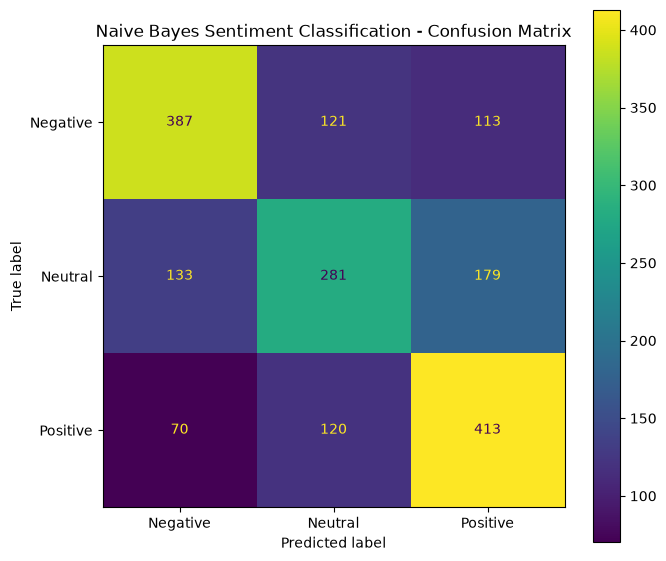

Confusion matrix saved successfully!
Saved at: ..\reports\naive_bayes_confusion_matrix.png


In [115]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

# Create reports folder if it does not exist
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Plot final Naive Bayes confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Naive Bayes Sentiment Classification - Confusion Matrix")
plt.tight_layout()

# Save figure
output_path = reports_dir / "naive_bayes_confusion_matrix.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")
print("Saved at:", output_path)

In [116]:
from sklearn.metrics import classification_report

# Generate detailed classification report
report_dict = classification_report(
    y_test,
    y_pred_nb,
    labels=["Negative", "Neutral", "Positive"],
    output_dict=True
)

# Convert report to DataFrame
classification_df = pd.DataFrame(report_dict).transpose()

# Round numerical values
classification_df = classification_df.round(4)

# Save classification report
classification_df.to_csv(
    "../reports/naive_bayes_classification_report.csv"
)

print("Classification report saved successfully!")
print("\nClass-wise Evaluation:")
print(classification_df)

Classification report saved successfully!

Class-wise Evaluation:
              precision  recall  f1-score    support
Negative         0.6559  0.6232    0.6391   621.0000
Neutral          0.5383  0.4739    0.5040   593.0000
Positive         0.5858  0.6849    0.6315   603.0000
accuracy         0.5949  0.5949    0.5949     0.5949
macro avg        0.5934  0.5940    0.5916  1817.0000
weighted avg     0.5943  0.5949    0.5925  1817.0000


In [117]:
# Save complete evaluation summary

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1"
    ],
    "Score": [
        final_accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_precision,
        weighted_recall,
        weighted_f1
    ]
})

final_metrics["Score"] = final_metrics["Score"].round(4)

final_metrics.to_csv(
    "../reports/final_naive_bayes_metrics.csv",
    index=False
)

print("Final evaluation summary saved successfully!")
print(final_metrics.to_string(index=False))

Final evaluation summary saved successfully!
            Metric  Score
          Accuracy 0.5949
   Macro Precision 0.5934
      Macro Recall 0.5940
          Macro F1 0.5916
Weighted Precision 0.5943
   Weighted Recall 0.5949
       Weighted F1 0.5925


In [119]:
# Save the final processed sentiment dataset

final_dataset_path = "../reports/final_sentiment_dataset.csv"

model_df.to_csv(
    final_dataset_path,
    index=False
)

print("Final processed dataset saved successfully!")
print("Shape:", model_df.shape)
print("Saved at:", final_dataset_path)

Final processed dataset saved successfully!
Shape: (9000, 4)
Saved at: ../reports/final_sentiment_dataset.csv
